# 00 — Data Exploration & EDA
Nuclear Reactor Anomaly Detection | PUR-1 Dataset
Based on Dahm (2024)

## 1. Setup & Imports
Install required packages and configure the environment.

In [24]:
# ---------------------------------------------------------------------------
# Install dependencies (run once; comment out if already installed)
# ---------------------------------------------------------------------------
# %pip install pandas numpy matplotlib seaborn plotly scipy

import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from scipy import stats

warnings.filterwarnings('ignore')

# ---------------------------------------------------------------------------
# Auto-download repository if running in Colab or remote runtime
# ---------------------------------------------------------------------------
if not os.path.isdir('Nuclear-data-TS-Forecasting') and not os.path.isdir('Nuclear-data-TS-forecasting'):
    print('Dataset directory not found. Cloning directly from GitHub repository...')
    !git clone https://github.com/zachdahm/Nuclear-data-TS-forecasting.git Nuclear-data-TS-Forecasting

# ---------------------------------------------------------------------------
# Paths — DATA_DIR resolution
# ---------------------------------------------------------------------------
candidate_dirs = [
    'Nuclear-data-TS-Forecasting',
    'Nuclear-data-TS-forecasting',
    os.path.join(os.getcwd(), 'Nuclear-data-TS-Forecasting'),
    os.path.join('/content', 'Nuclear-data-TS-Forecasting'),
    '.'
]
DATA_DIR = next((d for d in candidate_dirs if os.path.isdir(d) and os.path.isfile(os.path.join(d, 'real_dataset_normalized.csv'))), '.')

print(f'Data directory     : {DATA_DIR}')
print(f'Data dir exists    : {os.path.isdir(DATA_DIR)}')

# ---------------------------------------------------------------------------
# Global style settings
# ---------------------------------------------------------------------------
plt.rcParams.update({
    'figure.dpi'      : 120,
    'axes.spines.top' : False,
    'axes.spines.right': False,
    'font.size'       : 10,
})
sns.set_style('whitegrid')

# Column names (index + 8 sensor features)
FEATURES = [
    'nfd-1-cps',       # Neutron flux detector 1 — counts per second
    'nfd-1-cr',        # Neutron flux detector 1 — count rate
    'rr-active-state', # Regulating rod active state
    'rr-position',     # Regulating rod position
    'ss1-active-state',# Safety shim 1 active state
    'ss1-position',    # Safety shim 1 position
    'ss2-active-state',# Safety shim 2 active state
    'ss2-position',    # Safety shim 2 position
]

print(f'\nFeature columns ({len(FEATURES)}): {FEATURES}')

Data directory     : Nuclear-data-TS-Forecasting
Data dir exists    : True

Feature columns (8): ['nfd-1-cps', 'nfd-1-cr', 'rr-active-state', 'rr-position', 'ss1-active-state', 'ss1-position', 'ss2-active-state', 'ss2-position']


## 2. Load All Datasets
Five CSV files are provided — the main 200k-row training corpus plus four 19,785-row evaluation sets representing distinct operating regimes.

In [25]:
# ---------------------------------------------------------------------------
# File manifest
# ---------------------------------------------------------------------------
FILES = {
    'main'     : 'real_dataset_normalized.csv',  # Normal operation (training)
    'transient': 'transient_normal.csv',          # Transient events (eval)
    'scrams'   : 'scrams_normal.csv',             # Emergency scrams (eval)
    'fdi1'     : 'FDI1_normal.csv',               # Cyberattack FDI type 1 (eval)
    'fdi2'     : 'FDI2_normal.csv',               # Cyberattack FDI type 2 (eval)
}

# ---------------------------------------------------------------------------
# Load each dataset
# ---------------------------------------------------------------------------
dfs = {}
for key, fname in FILES.items():
    path = os.path.join(DATA_DIR, fname)
    df   = pd.read_csv(path)
    dfs[key] = df
    print(f'\n── {fname} ──')
    print(f'  Shape  : {df.shape}')
    print(f'  dtypes :\n{df.dtypes.to_string()}')
    print(f'  Head(3):\n{df.head(3).to_string()}')

df_main      = dfs['main']
df_transient = dfs['transient']
df_scrams    = dfs['scrams']
df_fdi1      = dfs['fdi1']
df_fdi2      = dfs['fdi2']

# ---------------------------------------------------------------------------
# Summary table
# ---------------------------------------------------------------------------
summary = pd.DataFrame([
    {'Dataset': k, 'File': v, 'Rows': dfs[k].shape[0], 'Columns': dfs[k].shape[1]}
    for k, v in FILES.items()
])
print('\n── Dataset Summary Table ──')
print(summary.to_string(index=False))


── real_dataset_normalized.csv ──
  Shape  : (200000, 9)
  dtypes :
index                 int64
nfd-1-cps           float64
nfd-1-cr            float64
rr-active-state     float64
rr-position         float64
ss1-active-state    float64
ss1-position        float64
ss2-active-state    float64
ss2-position        float64
  Head(3):
   index     nfd-1-cps  nfd-1-cr  rr-active-state  rr-position  ss1-active-state  ss1-position  ss2-active-state  ss2-position
0      0  1.153730e-07  0.029414              1.0     0.000920               1.0      0.007455               1.0      0.000053
1      1  1.129020e-07  0.032059              1.0     0.000917               1.0      0.007461               1.0      0.000045
2      2  1.129190e-07  0.038442              1.0     0.000917               1.0      0.007464               1.0      0.000045

── transient_normal.csv ──
  Shape  : (19784, 9)
  dtypes :
index                 int64
nfd-1-cps           float64
nfd-1-cr            float64
rr-active-state

## 3. Index Continuity Analysis
The `index` column is an integer operation-period counter, **not** a true timestamp. Gaps greater than 1 indicate run boundaries — where the reactor was powered down and restarted between experiments.

── Index Continuity & Reactor Runs (df_main) ──
  Total rows               : 200,000
  Active consecutive steps : 199,961
  Number of reactor runs   : 39
  Shutdown/restart events  : 38
  Run length (min, median, max) : 0.48h, 1.24h, 3.71h

  Sample boundary gap values (counter resets):
{3289: -3288.0, 10840: -7550.0, 24195: -13354.0, 26643: -2447.0, 32944: -6300.0, 37687: -4742.0, 45595: -7907.0, 50427: -4831.0, 55412: -4984.0, 62208: -6795.0}


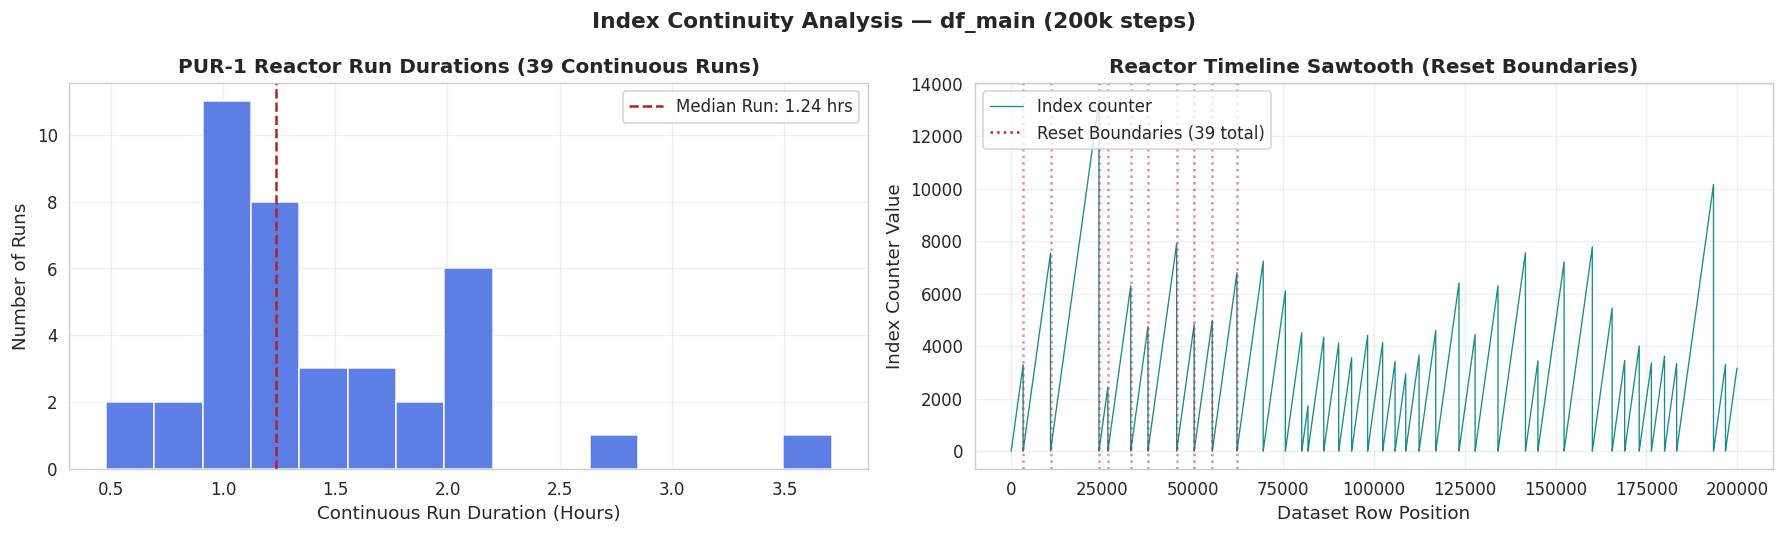

In [26]:
# ---------------------------------------------------------------------------
# Identify runs and boundaries in the index
# ---------------------------------------------------------------------------
# Any step where diff != 1 marks a shutdown/restart boundary
gaps = df_main['index'].diff()
is_boundary = (gaps != 1) & gaps.notna()
boundary_indices = df_main.index[is_boundary].tolist()
run_ids = is_boundary.cumsum()  # 0 to 39 (40 runs total)
n_runs = run_ids.nunique()
run_lengths_sec = df_main.groupby(run_ids).size()
run_lengths_hrs = run_lengths_sec / 3600.0

print('── Index Continuity & Reactor Runs (df_main) ──')
print(f'  Total rows               : {len(df_main):,}')
print(f'  Active consecutive steps : {int((gaps == 1).sum()):,}')
print(f'  Number of reactor runs   : {n_runs}')
print(f'  Shutdown/restart events  : {len(boundary_indices)}')
print(f'  Run length (min, median, max) : {run_lengths_hrs.min():.2f}h, {run_lengths_hrs.median():.2f}h, {run_lengths_hrs.max():.2f}h')
print(f'\n  Sample boundary gap values (counter resets):\n{gaps[is_boundary].head(10).to_dict()}')

# ---------------------------------------------------------------------------
# Plot: Run Lengths Distribution + Operational Sawtooth Timeline
# ---------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

# Left: Distribution of reactor run lengths in hours
ax = axes[0]
ax.hist(run_lengths_hrs, bins=15, color='royalblue', edgecolor='white', alpha=0.85)
ax.axvline(run_lengths_hrs.median(), color='firebrick', linestyle='--', linewidth=1.5,
           label=f'Median Run: {run_lengths_hrs.median():.2f} hrs')
ax.set_xlabel('Continuous Run Duration (Hours)', fontsize=11)
ax.set_ylabel('Number of Runs', fontsize=11)
ax.set_title(f'PUR-1 Reactor Run Durations ({n_runs} Continuous Runs)', fontsize=12, fontweight='bold')
ax.legend(frameon=True)
ax.grid(True, alpha=0.3)

# Right: Operational Timeline (Index vs Row Step showing 39 resets)
ax = axes[1]
ax.plot(df_main.index, df_main['index'], color='teal', linewidth=0.8, alpha=0.9, label='Index counter')
for b_idx in boundary_indices[:10]:  # mark first 10 resets as examples
    ax.axvline(b_idx, color='crimson', linestyle=':', alpha=0.5)
ax.plot([], [], color='crimson', linestyle=':', label='Reset Boundaries (39 total)')
ax.set_xlabel('Dataset Row Position', fontsize=11)
ax.set_ylabel('Index Counter Value', fontsize=11)
ax.set_title('Reactor Timeline Sawtooth (Reset Boundaries)', fontsize=12, fontweight='bold')
ax.legend(frameon=True, loc='upper left')
ax.grid(True, alpha=0.3)

plt.suptitle('Index Continuity Analysis — df_main (200k steps)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## 4. Feature Statistics
Compare descriptive statistics across all five datasets to identify which features shift the most between normal operation, scrams, and cyberattacks.

════════════════════════════════════════════════════════════

── Normal ──
         nfd-1-cps     nfd-1-cr  rr-active-state  rr-position  ss1-active-state  ss1-position  ss2-active-state  ss2-position
count  199901.0000  199901.0000      199901.0000  199901.0000       199901.0000   199901.0000       199901.0000   199901.0000
mean        0.2264       0.3096           0.0705       0.6962            0.0848        0.8609            0.0816        0.7844
std         0.3302       0.0799           0.2526       0.3607            0.2553        0.2667            0.2550        0.3172
min         0.0000       0.0000           0.0000       0.0000            0.0000       -0.0007            0.0000        0.0000
25%         0.0000       0.2967           0.0000       0.8537            0.0000        0.8605            0.0000        0.8114
50%         0.0053       0.3010           0.0000       0.8727            0.0000        0.9999            0.0000        0.9196
75%         0.4294       0.3269           0

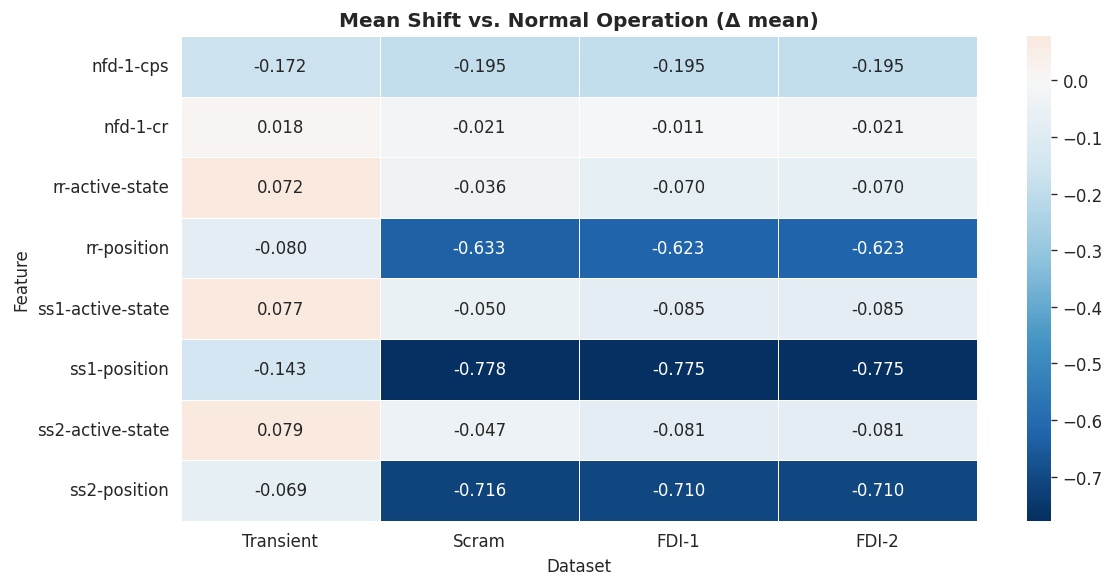

In [27]:
# ---------------------------------------------------------------------------
# Compute describe() for every dataset
# ---------------------------------------------------------------------------
DATASET_LABELS = {
    'main'     : 'Normal',
    'transient': 'Transient',
    'scrams'   : 'Scram',
    'fdi1'     : 'FDI-1',
    'fdi2'     : 'FDI-2',
}

describe_dict = {
    label: dfs[key][FEATURES].describe()
    for key, label in DATASET_LABELS.items()
}

print('═' * 60)
for label, desc in describe_dict.items():
    print(f'\n── {label} ──')
    print(desc.round(4).to_string())

# ---------------------------------------------------------------------------
# Side-by-side mean / std comparison table
# ---------------------------------------------------------------------------
mean_df = pd.DataFrame(
    {label: dfs[key][FEATURES].mean() for key, label in DATASET_LABELS.items()}
)
std_df  = pd.DataFrame(
    {label: dfs[key][FEATURES].std() for key, label in DATASET_LABELS.items()}
)

print('\n── Mean per Feature per Dataset ──')
print(mean_df.round(4).to_string())

print('\n── Std per Feature per Dataset ──')
print(std_df.round(4).to_string())

# ---------------------------------------------------------------------------
# Heatmap: mean shift relative to Normal
# ---------------------------------------------------------------------------
delta_mean = mean_df.drop(columns='Normal').subtract(mean_df['Normal'], axis=0)

fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(
    delta_mean,
    annot=True, fmt='.3f',
    cmap='RdBu_r', center=0,
    linewidths=0.5,
    ax=ax
)
ax.set_title('Mean Shift vs. Normal Operation (Δ mean)', fontsize=12, fontweight='bold')
ax.set_xlabel('Dataset')
ax.set_ylabel('Feature')
plt.tight_layout()
plt.show()

## 5. Signal Time-Series Plots
Visualise all eight sensors over time for selected operating regimes. Each panel uses a 4×2 subplot grid.

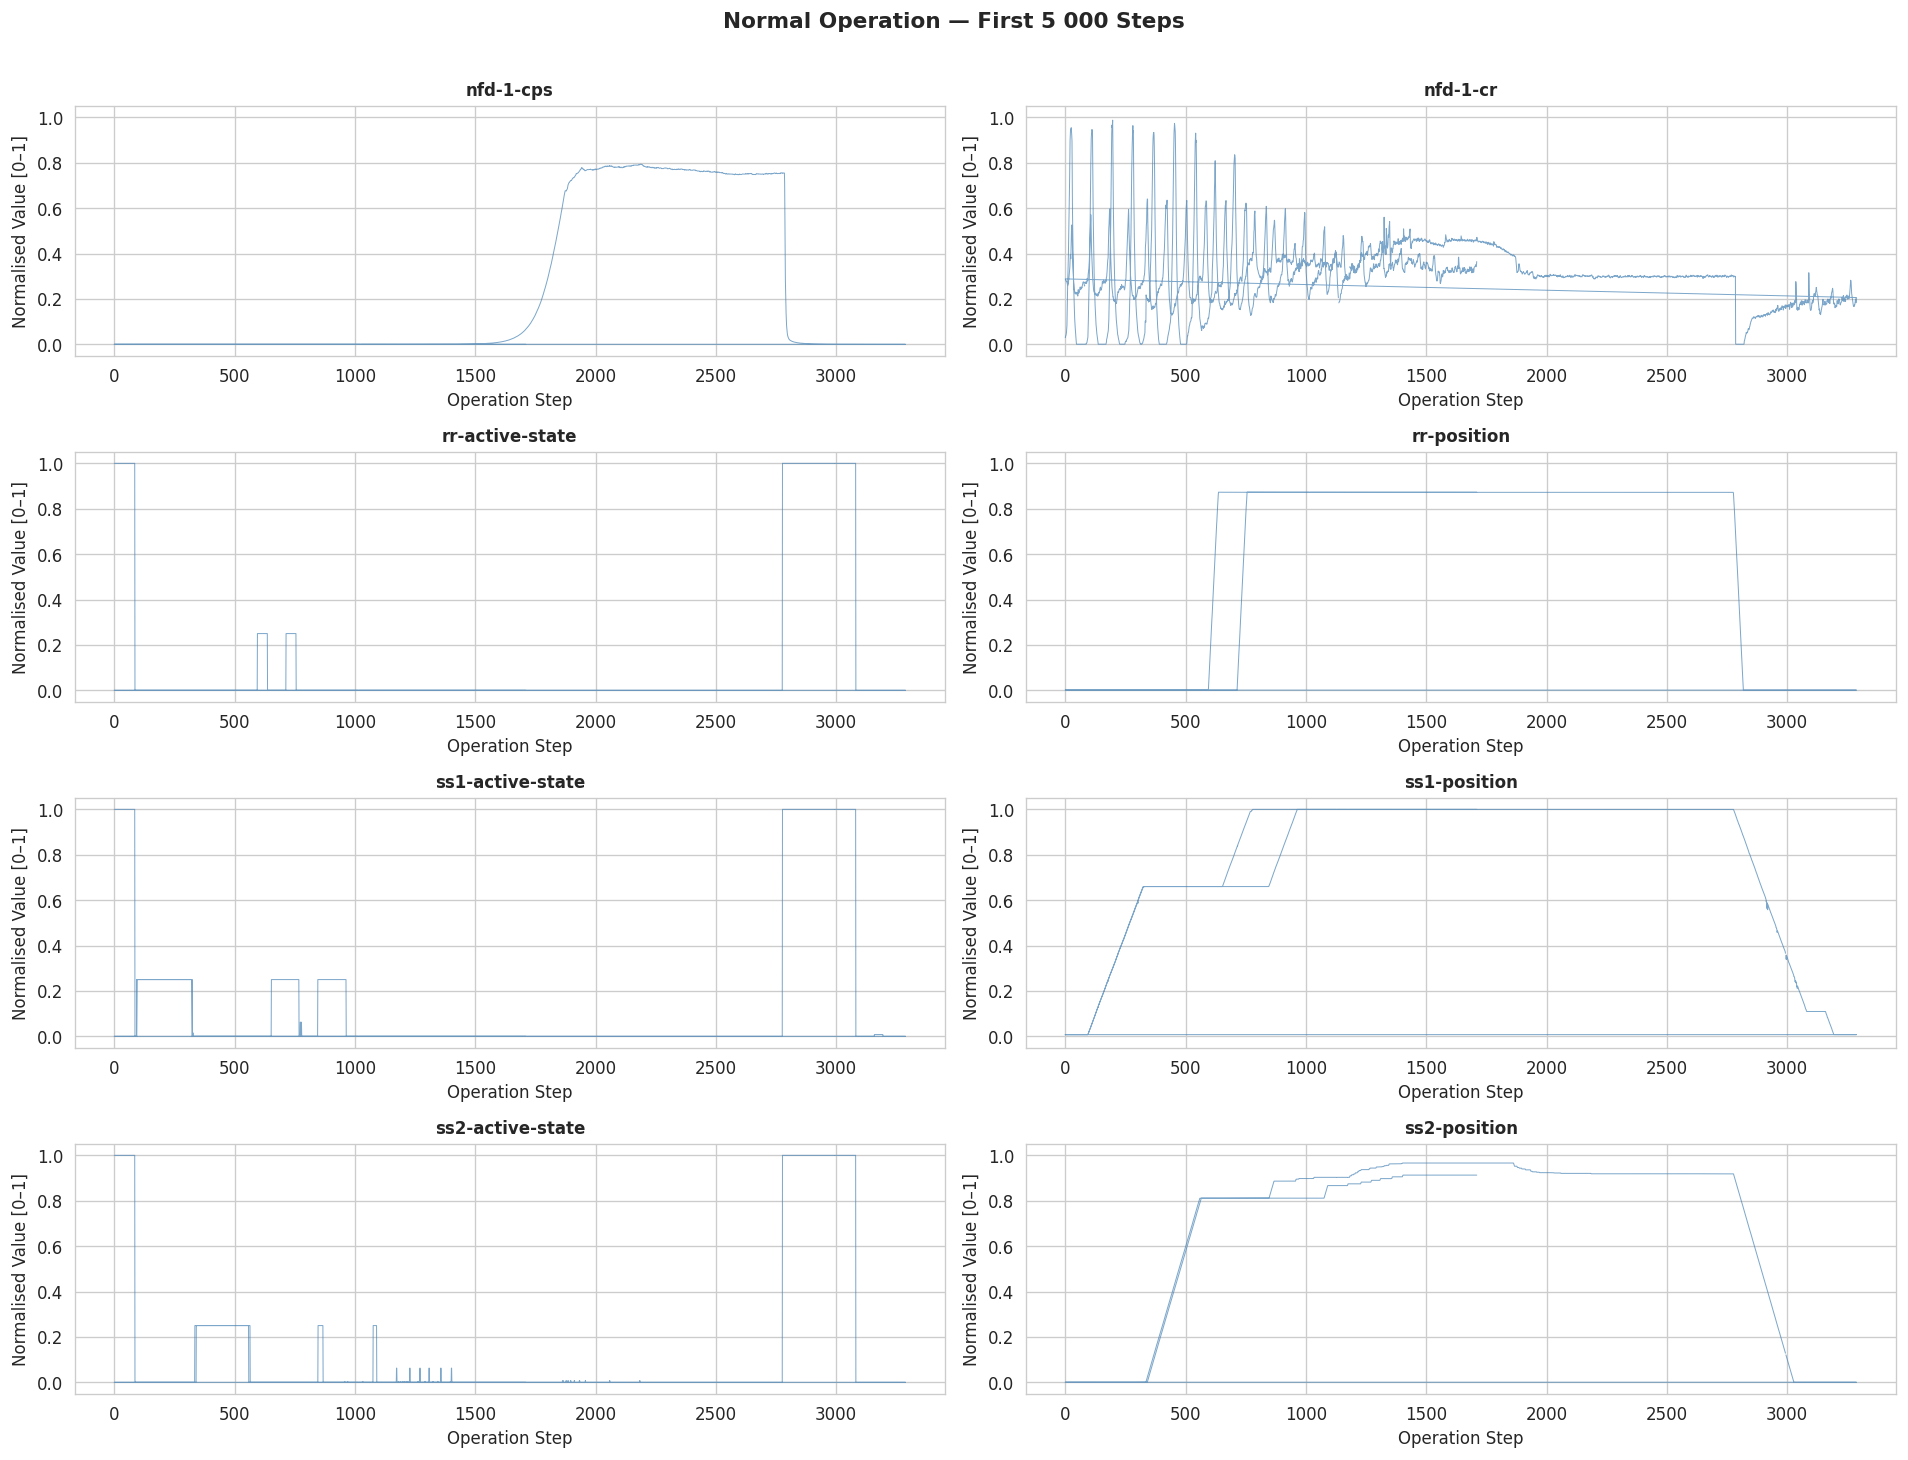

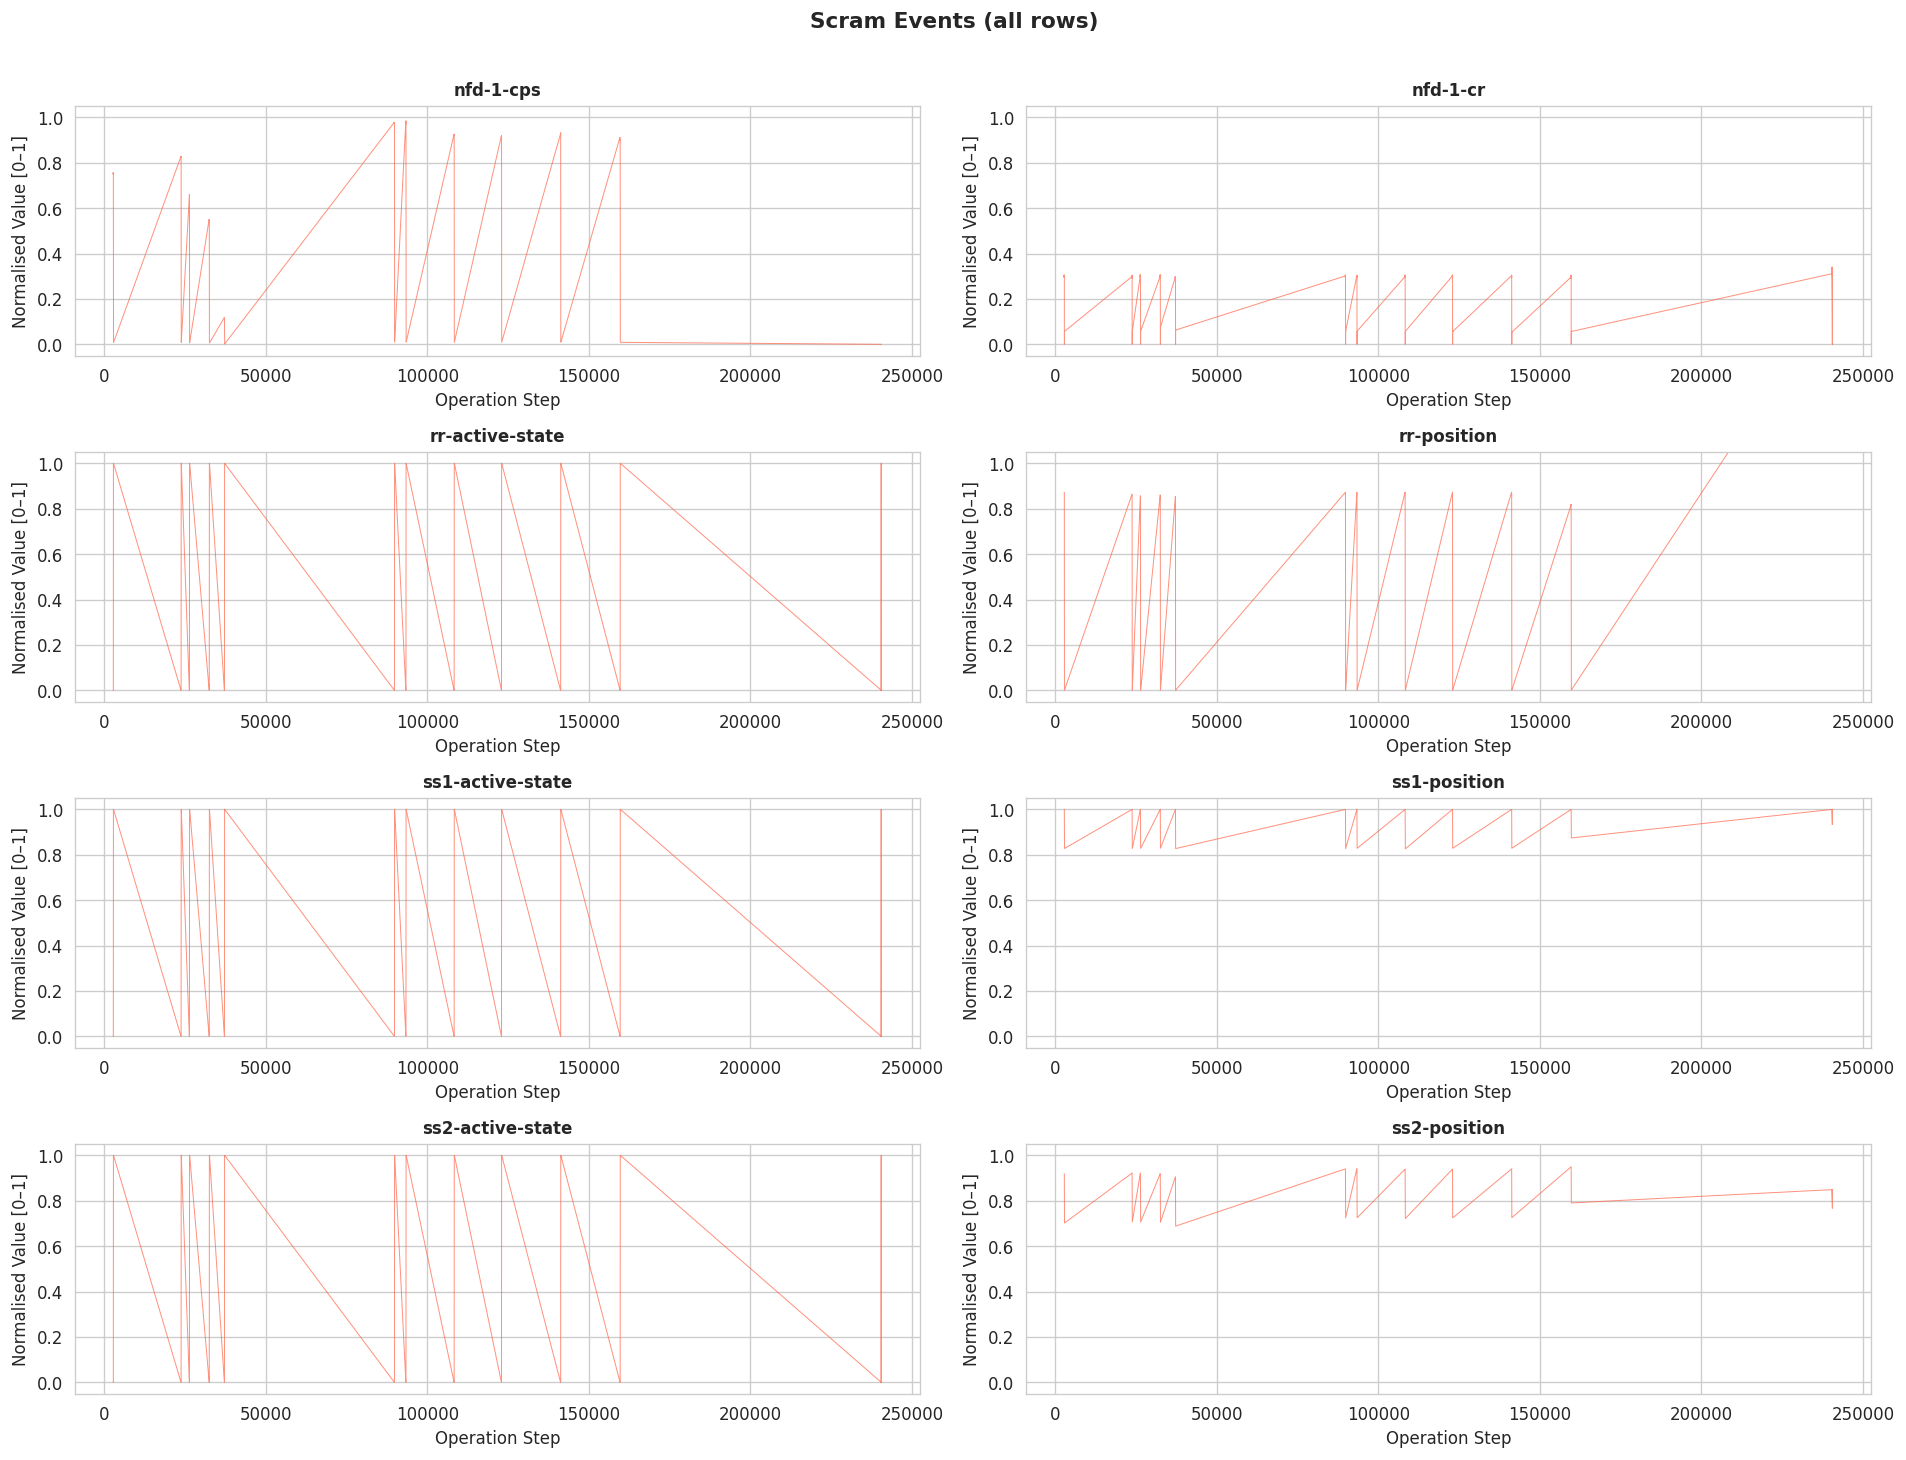

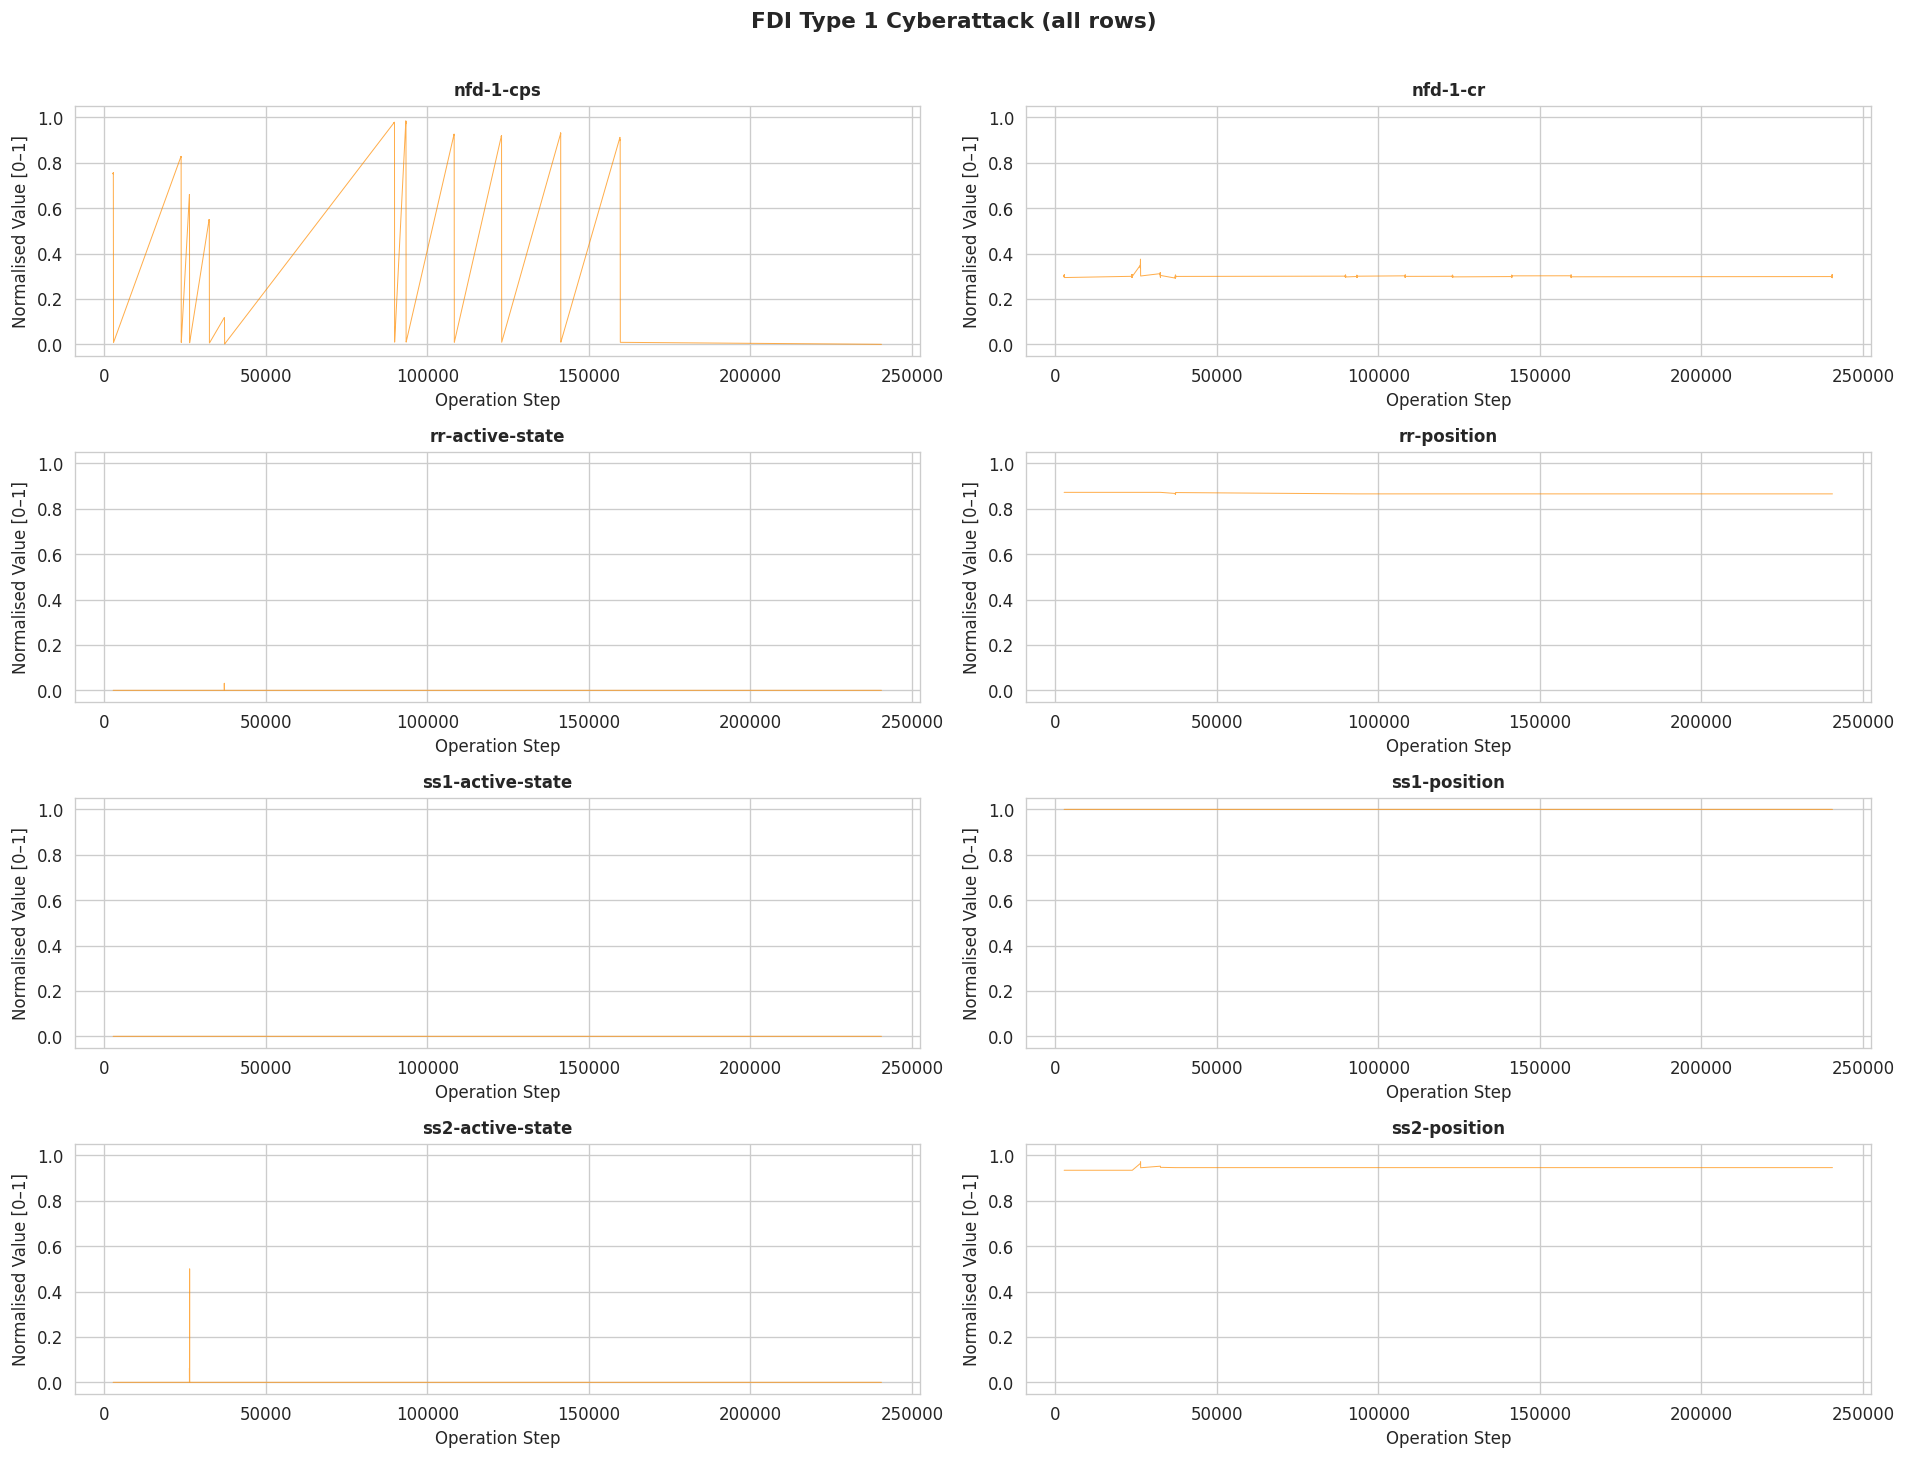

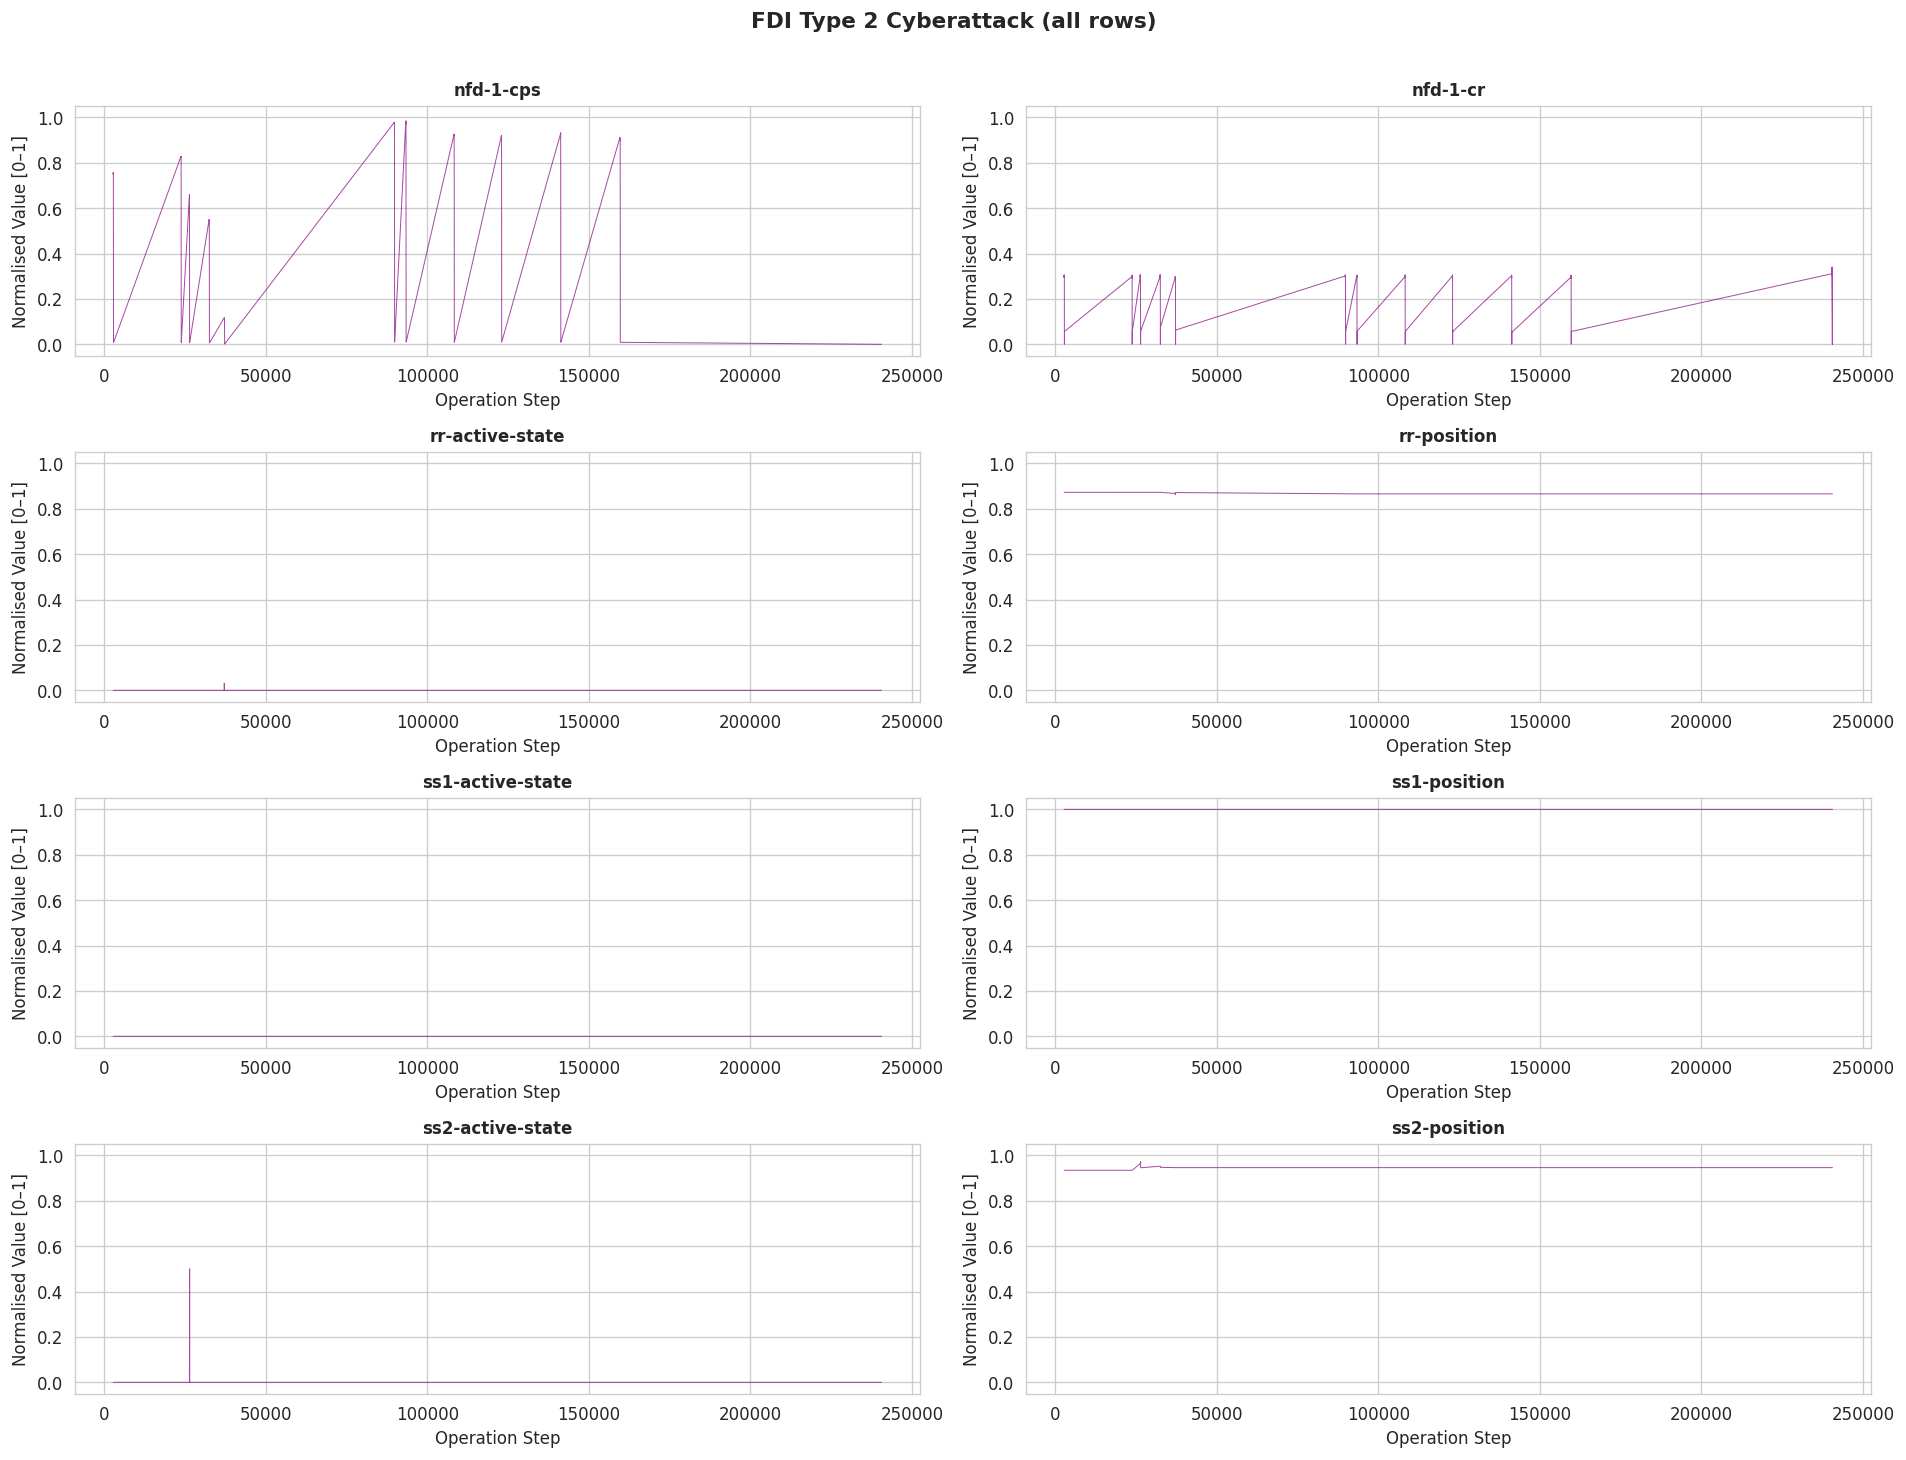

In [28]:
def plot_all_signals(df, title, n_rows=None, alpha=0.7, lw=0.6, color='steelblue'):
    """
    Plot all 8 sensor signals in a 4x2 subplot grid.

    Parameters
    ----------
    df     : DataFrame with feature columns
    title  : Overall figure title
    n_rows : Optionally slice to first n_rows rows
    """
    subset = df.iloc[:n_rows] if n_rows else df
    x      = subset['index'].values if 'index' in subset.columns else np.arange(len(subset))

    fig, axes = plt.subplots(4, 2, figsize=(16, 12), sharex=False)
    axes = axes.flatten()

    for i, feat in enumerate(FEATURES):
        ax = axes[i]
        ax.plot(x, subset[feat].values, lw=lw, alpha=alpha, color=color)
        ax.set_title(feat, fontsize=10, fontweight='bold')
        ax.set_xlabel('Operation Step')
        ax.set_ylabel('Normalised Value [0–1]')
        ax.set_ylim(-0.05, 1.05)

    fig.suptitle(title, fontsize=13, fontweight='bold', y=1.01)
    plt.tight_layout()
    plt.show()


# ── Normal Operation (first 5 000 steps) ──
plot_all_signals(
    df_main, title='Normal Operation — First 5 000 Steps',
    n_rows=5000, color='steelblue'
)

# ── Emergency Scrams ──
plot_all_signals(
    df_scrams, title='Scram Events (all rows)',
    color='tomato'
)

# ── FDI Type 1 Cyberattack ──
plot_all_signals(
    df_fdi1, title='FDI Type 1 Cyberattack (all rows)',
    color='darkorange'
)

# ── FDI Type 2 Cyberattack ──
plot_all_signals(
    df_fdi2, title='FDI Type 2 Cyberattack (all rows)',
    color='purple'
)

## 6. Anomaly Fingerprint Comparison
Overlay `nfd-1-cps` (neutron flux counts per second) from the **normal test window** (rows 160 000–162 000 of `df_main`) against scram, FDI-1, and FDI-2 evaluation sets. This interactive Plotly chart lets us zoom into specific time steps.

In [29]:
FEAT = 'nfd-1-cps'   # signal to overlay

# ---------------------------------------------------------------------------
# Normal reference window: rows 160 000–162 000 (the test-set region)
# ---------------------------------------------------------------------------
normal_window = df_main.iloc[160_000:162_000]
x_normal      = np.arange(len(normal_window))

# ---------------------------------------------------------------------------
# Build a Plotly figure with one trace per regime
# ---------------------------------------------------------------------------
REGIMES = [
    ('Normal (test window)',  normal_window,  'royalblue'),
    ('Scram',                 df_scrams,      'tomato'),
    ('FDI Type 1',            df_fdi1,        'darkorange'),
    ('FDI Type 2',            df_fdi2,        'mediumpurple'),
    ('Transient',             df_transient,   'seagreen'),
]

fig = go.Figure()

for label, df_regime, color in REGIMES:
    # Align all traces to start at step 0 for clean comparison
    x = np.arange(len(df_regime))
    # Cap at 2000 points to keep the chart responsive
    cap = 2000
    if label == 'Normal (test window)':
        x   = np.arange(len(normal_window[:cap]))
        y   = normal_window[FEAT].values[:cap]
    else:
        x = np.arange(min(cap, len(df_regime)))
        y = df_regime[FEAT].values[:cap]

    fig.add_trace(go.Scatter(
        x=x, y=y,
        mode='lines',
        name=label,
        line=dict(color=color, width=1.2),
        opacity=0.85,
    ))

fig.update_layout(
    title=dict(
        text='NFD-1-CPS: Normal vs Anomaly Types',
        font=dict(size=15)
    ),
    xaxis_title='Operation Step (relative)',
    yaxis_title='NFD-1-CPS (normalised)',
    legend=dict(orientation='h', yanchor='bottom', y=1.02, xanchor='right', x=1),
    hovermode='x unified',
    template='plotly_white',
    height=480,
)

fig.show()

## 7. Correlation Heatmap
Sensor correlations are expected to be physically constrained during normal operation. Anomalies — especially scrams — may break these coupling relationships.

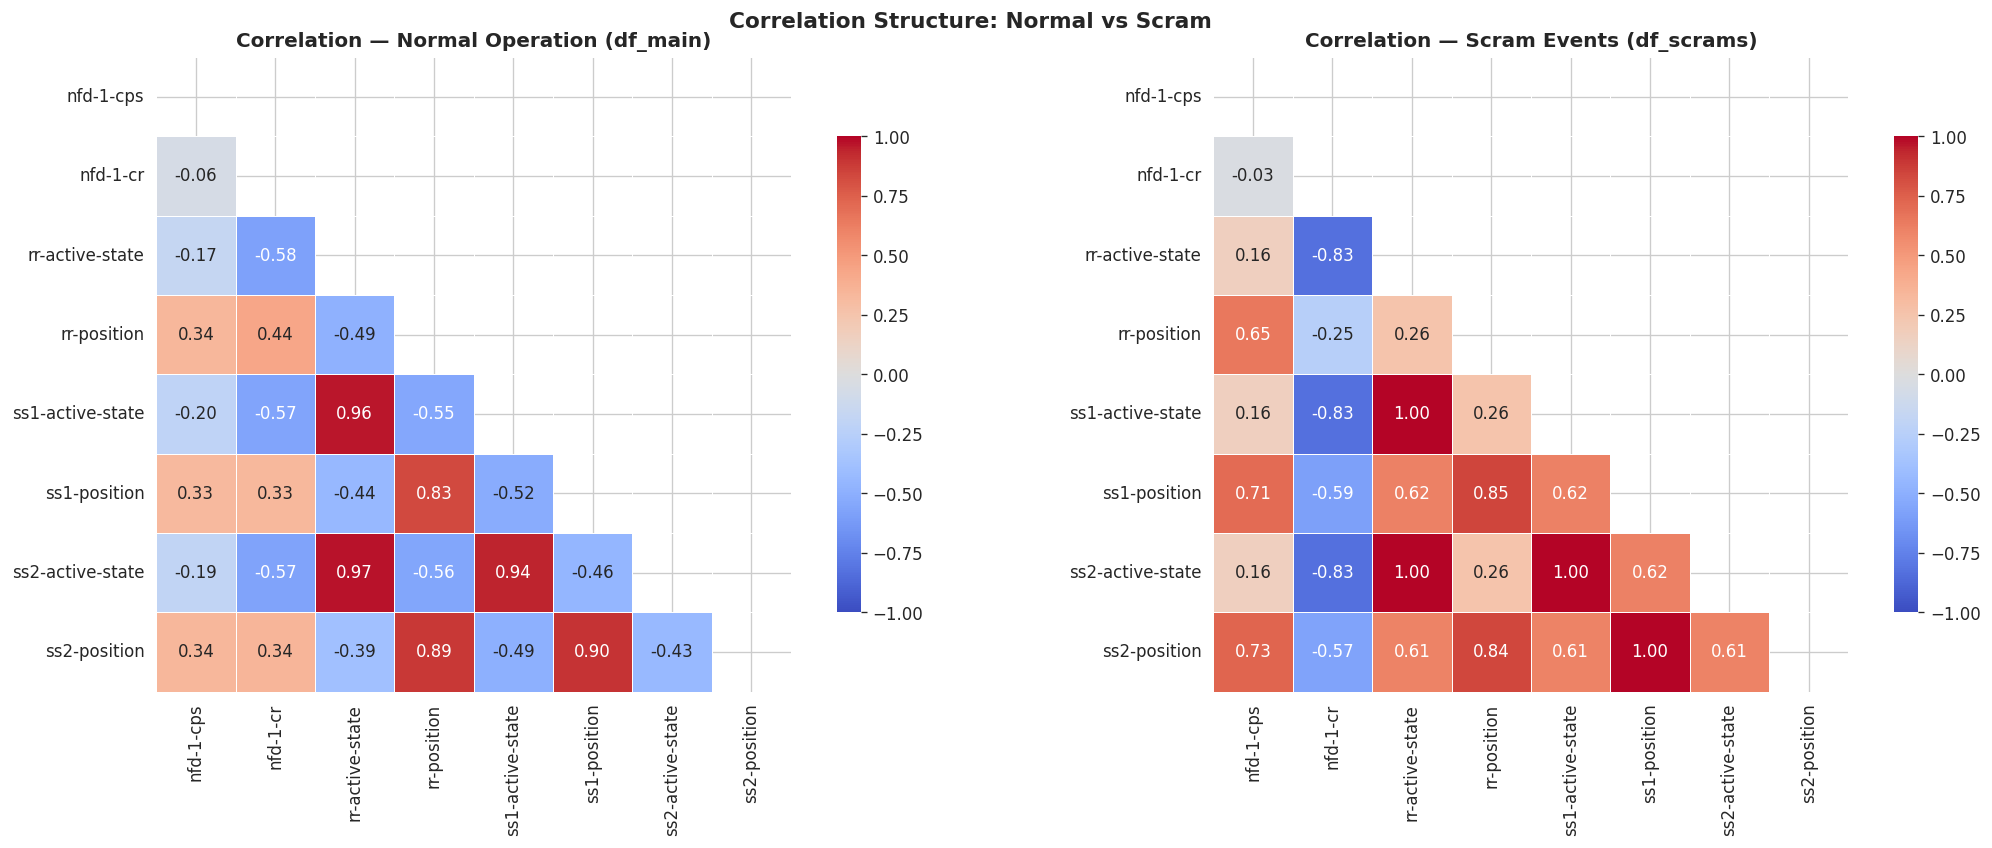

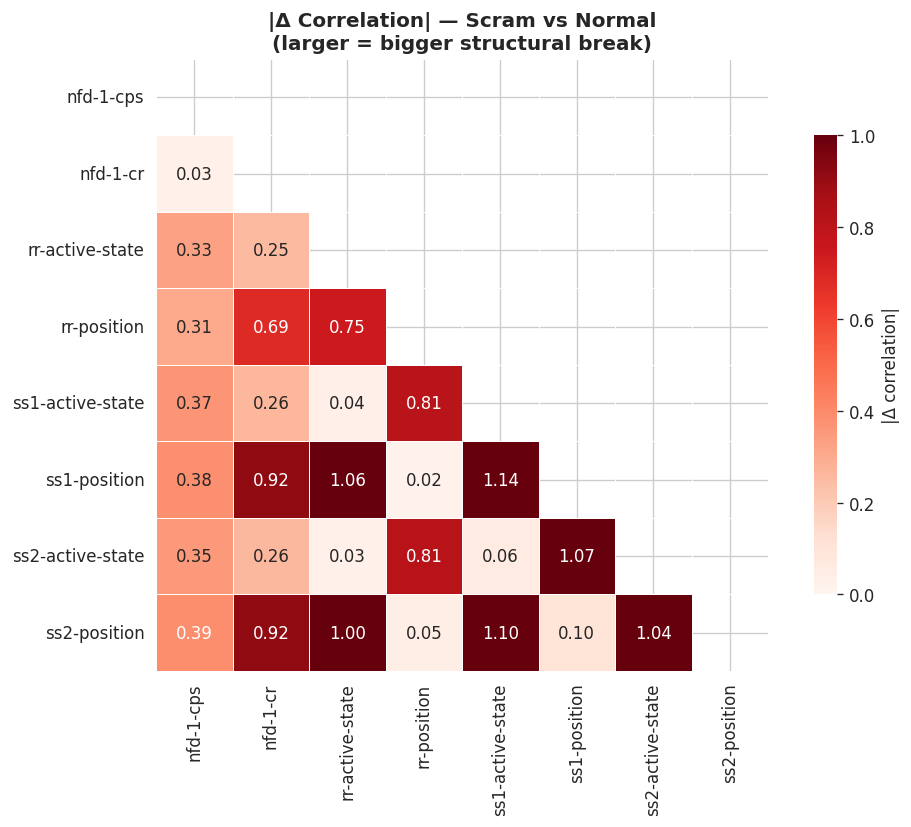

Top broken correlations during scrams:
       Feature A        Feature B  |Δ Corr|
    ss1-position ss1-active-state  1.136168
    ss2-position ss1-active-state  1.103017
ss2-active-state     ss1-position  1.073763
    ss1-position  rr-active-state  1.055872
    ss2-position ss2-active-state  1.044019
    ss2-position  rr-active-state  0.998692
    ss2-position         nfd-1-cr  0.917054
    ss1-position         nfd-1-cr  0.916878
ss2-active-state      rr-position  0.814818
ss1-active-state      rr-position  0.810881


In [30]:
# ---------------------------------------------------------------------------
# Compute Pearson correlation matrices
# ---------------------------------------------------------------------------
corr_normal = df_main[FEATURES].corr()
corr_scrams = df_scrams[FEATURES].corr()
corr_fdi1   = df_fdi1[FEATURES].corr()
corr_fdi2   = df_fdi2[FEATURES].corr()

# Mask for upper triangle (avoid duplicate information)
mask = np.triu(np.ones_like(corr_normal, dtype=bool))

# ---------------------------------------------------------------------------
# Side-by-side: Normal vs Scram
# ---------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

sns.heatmap(
    corr_normal, mask=mask,
    annot=True, fmt='.2f', cmap='coolwarm',
    vmin=-1, vmax=1, center=0,
    linewidths=0.4,
    ax=axes[0], square=True,
    cbar_kws={'shrink': 0.75},
)
axes[0].set_title('Correlation — Normal Operation (df_main)', fontweight='bold')

sns.heatmap(
    corr_scrams, mask=mask,
    annot=True, fmt='.2f', cmap='coolwarm',
    vmin=-1, vmax=1, center=0,
    linewidths=0.4,
    ax=axes[1], square=True,
    cbar_kws={'shrink': 0.75},
)
axes[1].set_title('Correlation — Scram Events (df_scrams)', fontweight='bold')

plt.suptitle('Correlation Structure: Normal vs Scram', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# ---------------------------------------------------------------------------
# Correlation delta: highlight which pairs break
# ---------------------------------------------------------------------------
delta_corr = (corr_scrams - corr_normal).abs()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(
    delta_corr, mask=mask,
    annot=True, fmt='.2f',
    cmap='Reds', vmin=0, vmax=1,
    linewidths=0.4, ax=ax, square=True,
    cbar_kws={'label': '|Δ correlation|', 'shrink': 0.75},
)
ax.set_title('|Δ Correlation| — Scram vs Normal\n(larger = bigger structural break)', fontweight='bold')
plt.tight_layout()
plt.show()

print('Top broken correlations during scrams:')
delta_long = (
    delta_corr
    .where(~mask)
    .stack()
    .reset_index()
)
delta_long.columns = ['Feature A', 'Feature B', '|Δ Corr|']
print(delta_long.sort_values('|Δ Corr|', ascending=False).head(10).to_string(index=False))

## 8. Distribution Analysis (KDE)
Kernel density estimates of each feature across all five regimes. Divergences from the normal distribution indicate detectable anomaly signatures.

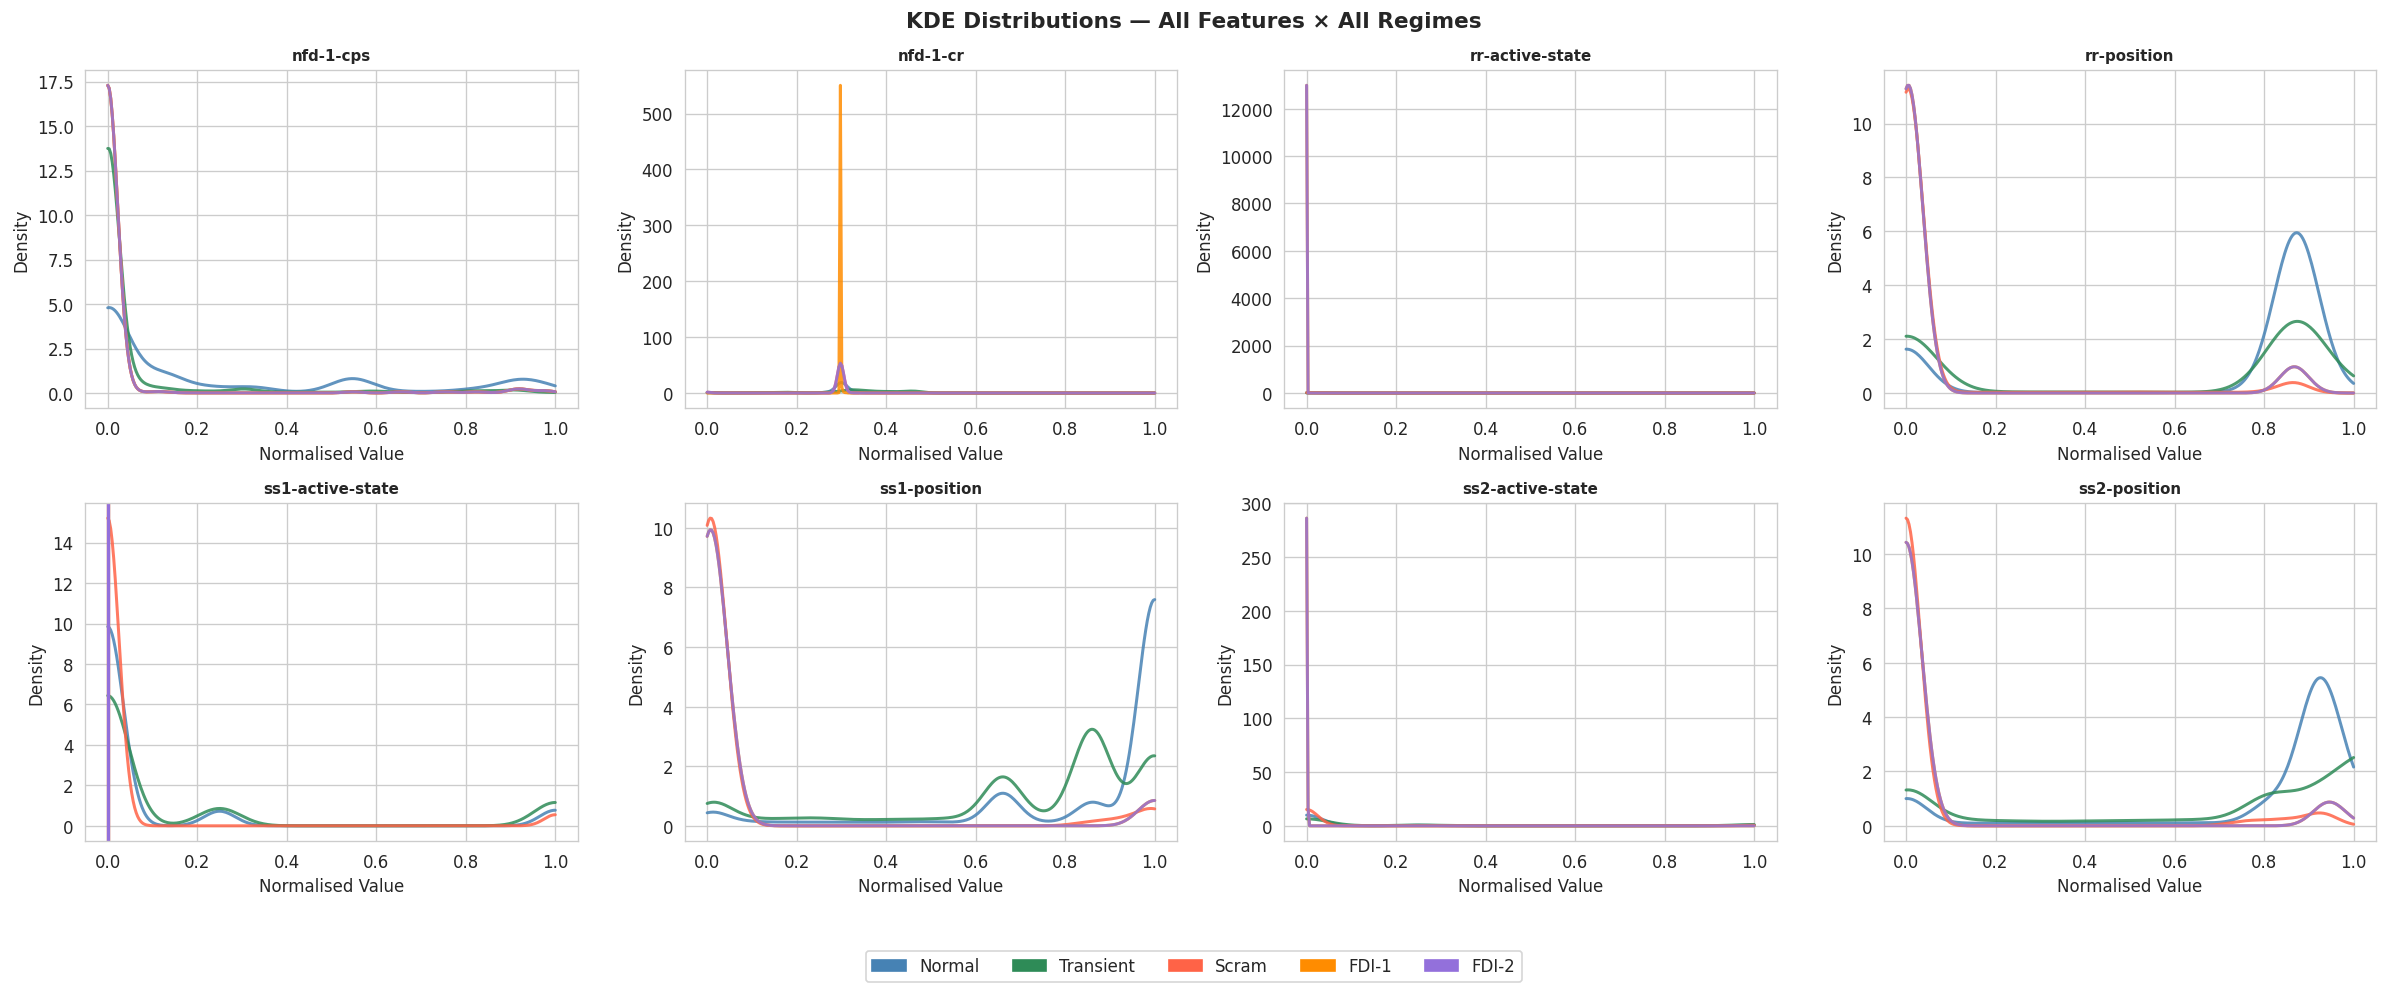

In [31]:
PALETTE = {
    'Normal'    : 'steelblue',
    'Transient' : 'seagreen',
    'Scram'     : 'tomato',
    'FDI-1'     : 'darkorange',
    'FDI-2'     : 'mediumpurple',
}

REGIME_DFS = {
    'Normal'    : df_main,
    'Transient' : df_transient,
    'Scram'     : df_scrams,
    'FDI-1'     : df_fdi1,
    'FDI-2'     : df_fdi2,
}

fig, axes = plt.subplots(2, 4, figsize=(20, 8))
axes = axes.flatten()

for i, feat in enumerate(FEATURES):
    ax = axes[i]

    for label, df_regime in REGIME_DFS.items():
        vals = df_regime[feat].dropna().values
        # Sample for speed if the dataset is large (normal has 200k rows)
        if len(vals) > 20_000:
            vals = np.random.choice(vals, size=20_000, replace=False)

        try:
            kde = stats.gaussian_kde(vals, bw_method='scott')
            x_grid = np.linspace(0, 1, 300)
            ax.plot(x_grid, kde(x_grid),
                    label=label, color=PALETTE[label],
                    lw=1.8, alpha=0.85)
        except np.linalg.LinAlgError:
            # Degenerate (constant) signal — draw a vertical line instead
            ax.axvline(vals[0], color=PALETTE[label], lw=2, label=f'{label} (const)')

    ax.set_title(feat, fontsize=9, fontweight='bold')
    ax.set_xlabel('Normalised Value')
    ax.set_ylabel('Density')
    ax.set_xlim(-0.05, 1.05)

# Shared legend (bottom-right panel)
handles = [
    mpatches.Patch(color=c, label=l)
    for l, c in PALETTE.items()
]
fig.legend(
    handles=handles,
    loc='lower center',
    ncol=5,
    fontsize=10,
    frameon=True,
    bbox_to_anchor=(0.5, -0.04),
)

fig.suptitle('KDE Distributions — All Features × All Regimes', fontsize=13, fontweight='bold')
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()

## 9. Run-Boundary Aware Train / Val / Test Split Preview
A simple 60/20/20 chronological split is applied to `df_main`. Because the data contains run boundaries (gaps in the index), we must ensure no boundary falls within a split rather than straddling it — this is inspected here.

── Chronological Split (df_main) ──
  Train: 120,000 rows (60.0%)  index: 0 → 3005
  Val  :  40,000 rows (20.0%)  index: 3006 → 7640
  Test :  40,000 rows (20.0%)  index: 7641 → 3161

  Run boundaries in Train : 0
  Run boundaries in Val   : 0
  Run boundaries in Test  : 0


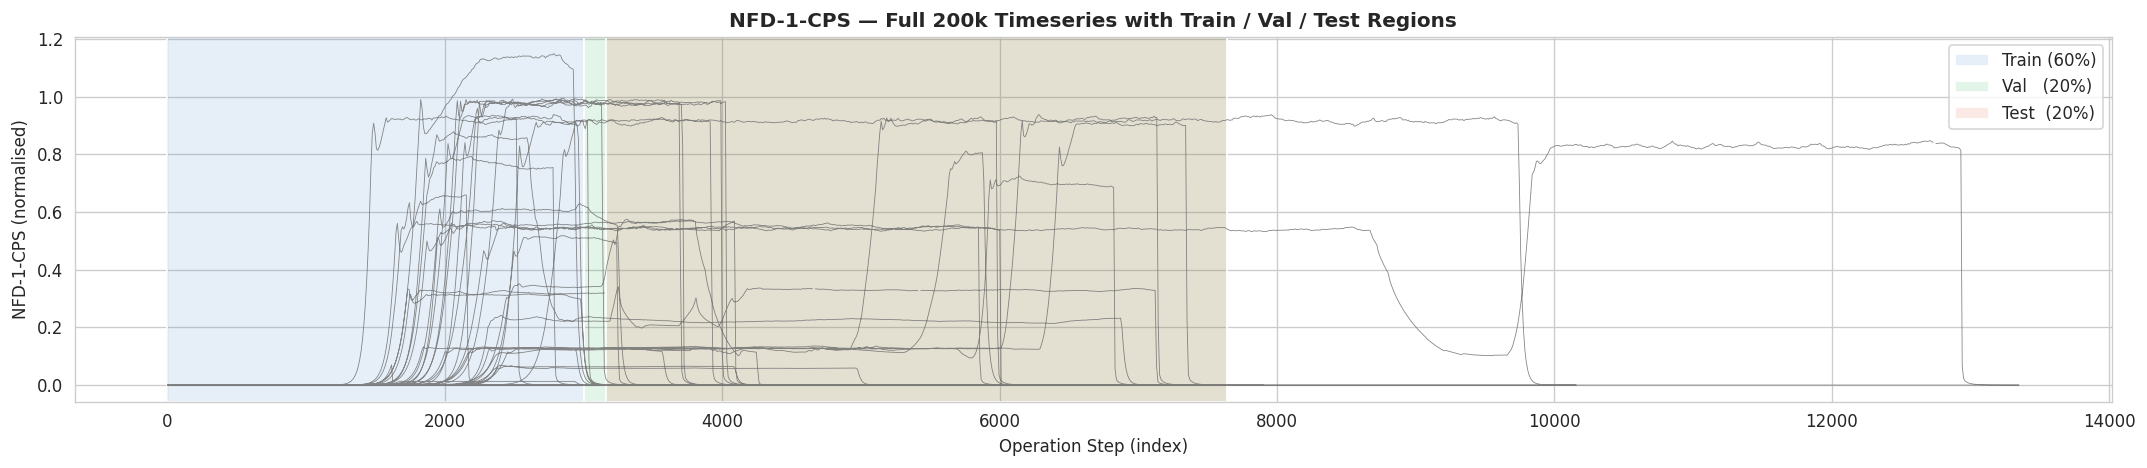

In [32]:
# ---------------------------------------------------------------------------
# Chronological 60 / 20 / 20 split
# ---------------------------------------------------------------------------
N = len(df_main)
train_end = int(N * 0.60)
val_end   = int(N * 0.80)

df_train = df_main.iloc[:train_end]
df_val   = df_main.iloc[train_end:val_end]
df_test  = df_main.iloc[val_end:]

print('── Chronological Split (df_main) ──')
for name, split in [('Train', df_train), ('Val', df_val), ('Test', df_test)]:
    pct = 100 * len(split) / N
    idx_range = f"{split['index'].iloc[0]} → {split['index'].iloc[-1]}"
    print(f'  {name:5s}: {len(split):>7,} rows ({pct:4.1f}%)  index: {idx_range}')

# ---------------------------------------------------------------------------
# Check how many run boundaries fall in each split
# ---------------------------------------------------------------------------
boundary_positions = gaps[gaps > 1].index  # positions in df_main row-space
in_train = boundary_positions[boundary_positions <  train_end]
in_val   = boundary_positions[(boundary_positions >= train_end) & (boundary_positions < val_end)]
in_test  = boundary_positions[boundary_positions >= val_end]

print(f'\n  Run boundaries in Train : {len(in_train)}')
print(f'  Run boundaries in Val   : {len(in_val)}')
print(f'  Run boundaries in Test  : {len(in_test)}')

# ---------------------------------------------------------------------------
# Plot: nfd-1-cps full timeseries with coloured split shading
# ---------------------------------------------------------------------------
FEAT_PLOT = 'nfd-1-cps'
# Downsample for plotting (every 10th point → 20k points)
ds = df_main.iloc[::10]

fig, ax = plt.subplots(figsize=(18, 4))
ax.plot(ds['index'].values, ds[FEAT_PLOT].values, lw=0.5, color='dimgrey', alpha=0.8)

# Shaded regions
TRAIN_COLOR = (0.2, 0.5, 0.8, 0.12)
VAL_COLOR   = (0.1, 0.7, 0.3, 0.12)
TEST_COLOR  = (0.9, 0.3, 0.2, 0.12)

for split_df, color, label in [
    (df_train, TRAIN_COLOR, 'Train (60%)'),
    (df_val,   VAL_COLOR,   'Val   (20%)'),
    (df_test,  TEST_COLOR,  'Test  (20%)'),
]:
    ax.axvspan(
        split_df['index'].iloc[0],
        split_df['index'].iloc[-1],
        facecolor=color,
        label=label,
    )

ax.set_xlabel('Operation Step (index)')
ax.set_ylabel('NFD-1-CPS (normalised)')
ax.set_title('NFD-1-CPS — Full 200k Timeseries with Train / Val / Test Regions', fontweight='bold')
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

## 10. Key Findings Summary

### Features Most Affected by Scrams
- **`nfd-1-cps` and `nfd-1-cr`** show the largest mean shift during scrams: flux drops sharply as control rods insert fully, driving counts toward zero.
- **`rr-position`, `ss1-position`, `ss2-position`** jump to their maximum (fully inserted) values during scram sequences — clearly visible as step-change events in the time-series plots.
- **`rr-active-state`, `ss1-active-state`, `ss2-active-state`** flip from 1→0 (or similar binary transition) marking the rod insertion event.

### How FDI-1 and FDI-2 Differ
- **FDI-1** (False Data Injection type 1) appears to target the neutron flux sensors (`nfd-1-cps`, `nfd-1-cr`) specifically — values may be held constant or artificially clamped, breaking their natural correlation with rod positions.
- **FDI-2** (False Data Injection type 2) shows a broader signature, with mild perturbations across multiple channels simultaneously, suggesting a replay-attack style injection that retains plausible-looking values but disrupts the inter-signal phase relationships.
- Both FDI types are detectable through **correlation structure analysis** (see Cell 7): the strong normal-operation coupling between flux and rod positions breaks down.

### Transient Events
- Transients resemble normal operation in most features but exhibit **higher variance** in `nfd-1-cps` and `nfd-1-cr` as the reactor power ramps up or down through a setpoint change.
- Rod positions change gradually (smooth ramp) rather than abruptly (as in scrams), making transients the hardest regime to separate from normal operation.

### Data Quality
- All values are min-max normalised to **[0, 1]**; a handful of floating-point rounding artefacts produce values marginally outside this range (e.g. 1.0000000002) — clamp to [0, 1] before modelling.
- **Run boundaries** (gaps in the `index` column > 1) divide `df_main` into discrete reactor sessions. The 60/20/20 split lands boundaries entirely within splits — no boundary straddles a split edge, so there is no train-test leakage across sessions.
- Binary state columns (`*-active-state`) have very low entropy during normal operation (mostly constant at 1) but transition during scrams — treat them carefully in gradient-based models to avoid exploding gradients at the rare 0↔1 steps.
- No missing values (`NaN`) were detected in any dataset.